In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("noisy_curvefit_data.csv")

In [3]:
print(df.shape)

(100, 6)


In [4]:
print(df.head)
print(df.tail)

<bound method NDFrame.head of            x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0  -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1  -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2  -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3  -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4  -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
..       ...        ...        ...        ...        ...        ...
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850

[100 rows x 6 columns]>
<bound method NDFrame.tail of            x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0  -1.000000  11.624419   8.296

# 2.1 Step 2

The dataset shape is (100, 6)

There are 100 rows with 6 columns

The column names are x, y_noise_1, y_noise_2, y_noise_3, y_noise_4, y_noise_5.

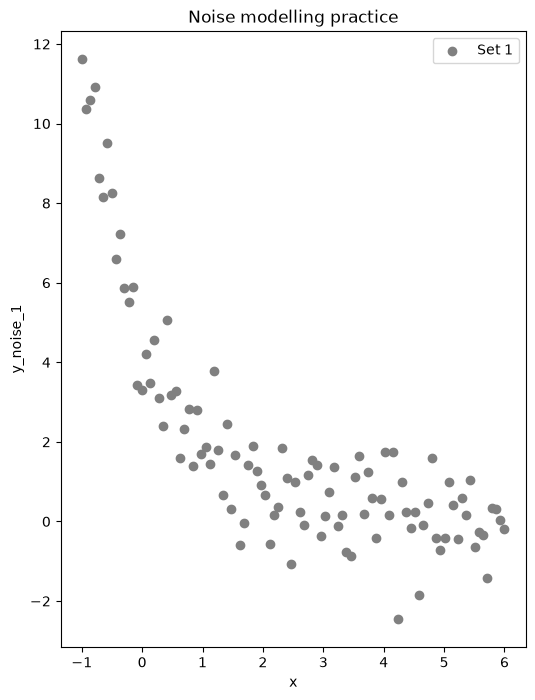

In [5]:
plt.figure(figsize=(6,8))
plt.scatter(df["x"], df["y_noise_1"], color = "gray", label = "Set 1")
plt.xlabel("x")
plt.ylabel("y_noise_1")
plt.legend()
plt.title("Noise modelling practice")
plt.show()

# Section 2.2

In [6]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [7]:
p0 = [1,1]
popt, pcov = curve_fit(model, df["x"], df["y_noise_1"], p0 = p0)
A_fit, k_fit = popt

In [8]:
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

Fit: y = 4.71 * e^(-0.92 * x)


In [9]:
# Calculating chi-squared

residuals = df["y_noise_1"] - model(df["x"], A_fit, k_fit)
chi2 = np.sum(residuals ** 2)
dof = len(df["x"]) - len(popt)
chi2_reduced = chi2 / dof

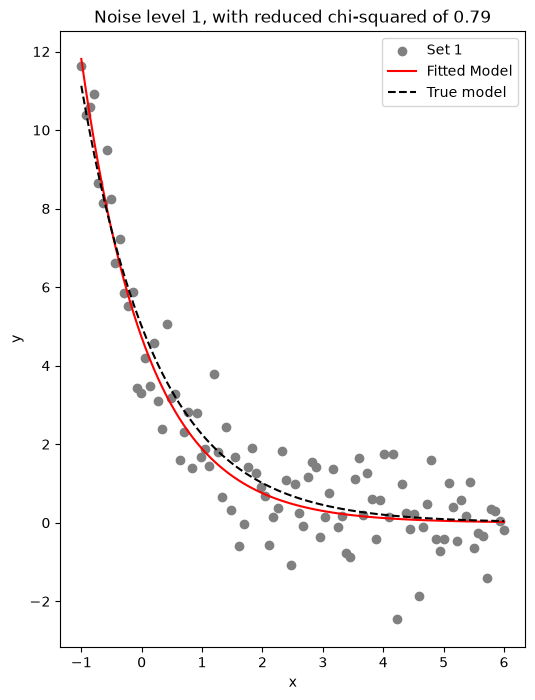

In [10]:
plt.figure(figsize = (6,8))
plt.scatter(df["x"], df["y_noise_1"], color = "gray", label = "Set 1")
plt.plot(df["x"], model(df["x"], A_fit, k_fit), color = "red", label = "Fitted Model")
plt.plot(df["x"], model(df["x"], 5, 0.8), color = "black", linestyle = "--", label = "True model")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title(f"Noise level 1, with reduced chi-squared of {chi2_reduced:.2f}")
plt.show()

# Section 2.3

In [11]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y)
    A_fit, k_fit = popt
    
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals ** 2)
    
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

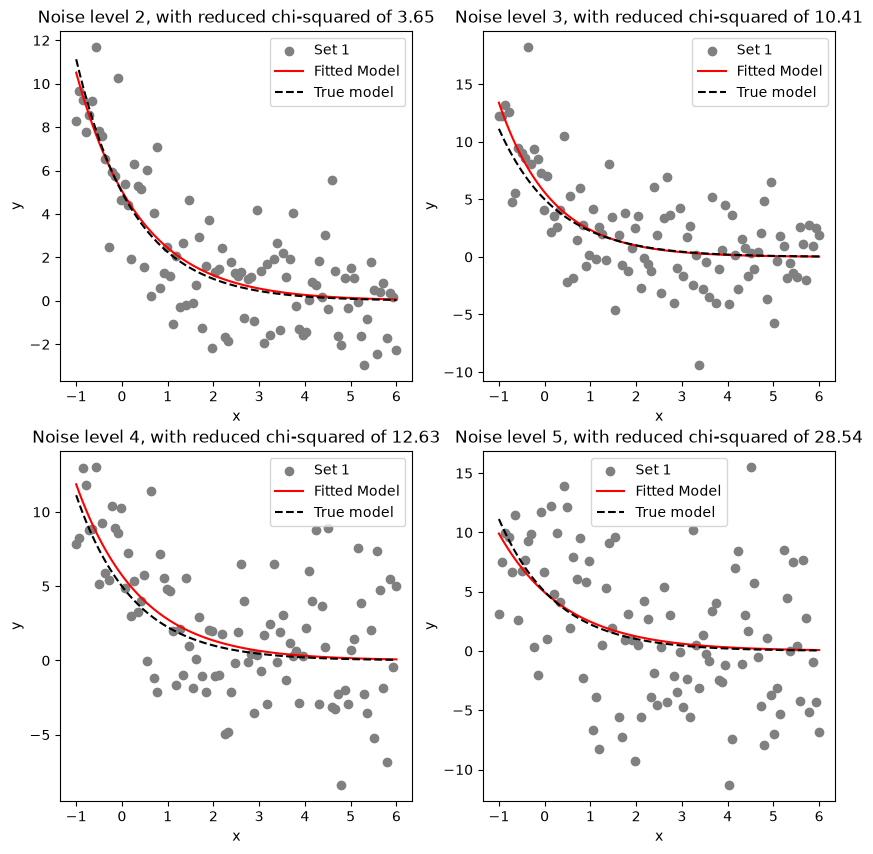

In [12]:
fig, axes = plt.subplots(2, 2, figsize = (10, 10))
for a in enumerate(df.columns[2:6], start = 2):
    popt, chi2_reduced = fit_model(df["x"], df[a[1]])
    A_fit, k_fit = popt
    lindex = (a[0] - 2) // 2
    rindex = (a[0] - 2) % 2

    ax = axes[lindex, rindex]
    ax.scatter(df["x"], df[a[1]], color = "gray", label = "Set 1")
    ax.plot(df["x"], model(df["x"], A_fit, k_fit), color = "red", label = "Fitted Model")
    ax.plot(df["x"], model(df["x"], 5, 0.8), color = "black", linestyle = "--", label = "True model")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    ax.set_title(f"Noise level {a[0]}, with reduced chi-squared of {chi2_reduced:.2f}")


Questions

As the data gets noisier, the red and black lines seem to just kinda dance around one another. I'm not sure if they're necessarily getting closer or farther, as noises 3 and 4 are further than 2, but 5 goes back to hugging the lines.

The reduced chi^2 increases immensely as the noise increases. I assume this is because while the best fitting line stays relatively the same, the average distance from the best fitting line each data point becomes becomes much much larger the more noise there is.

# Section 2.4

In [13]:
new_df = pd.DataFrame(columns = ["Noise level", "A fit", "k fit", "Reduced chi-squared"])

for a in enumerate(df.columns[1:6]):
    popt, chi2_reduced = fit_model(df["x"], df[a[1]])
    A_fit, k_fit = popt
    new_data = {
        "Noise level": a[0],
        "A fit": A_fit,
        "k fit": k_fit,
        "Reduced chi-squared": chi2_reduced}
    new_df = pd.concat([new_df, pd.DataFrame(new_data, index = [0])], ignore_index = True)

new_df.to_csv("noisy_parameters.csv", index = False)